<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/XGBHECKTOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 6.69MB/s]


Dataset shape: (588, 9)

Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

Target distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64

================== FOLD 1/3 ==================
Training samples: 392
Validation samples: 196
Automatic class weights: {0: 5.0256410256410255, 1: 0.5552407932011332}
XGBoost scale_pos_weight: 0.11048158640226628
SMOTE: No
Selected threshold: 0.865

Validation metrics:
Accuracy               0.5153
Balanced_Accuracy      0.7316
Precision              1.0000
Recall                 0.4633
F1                     0.6332
Threshold              0.8650
ROC_AUC                0.7707
PR_AUC                 0.9711
Fold                   1.0000
N_Train              392.0000
N_Validation         196.0000
Scale_Pos_Weight       0.1105
dtype: float64

================== FOLD 2/3 ==================
Training samples: 392
Validation samples: 196
Automatic class weights: {0: 5

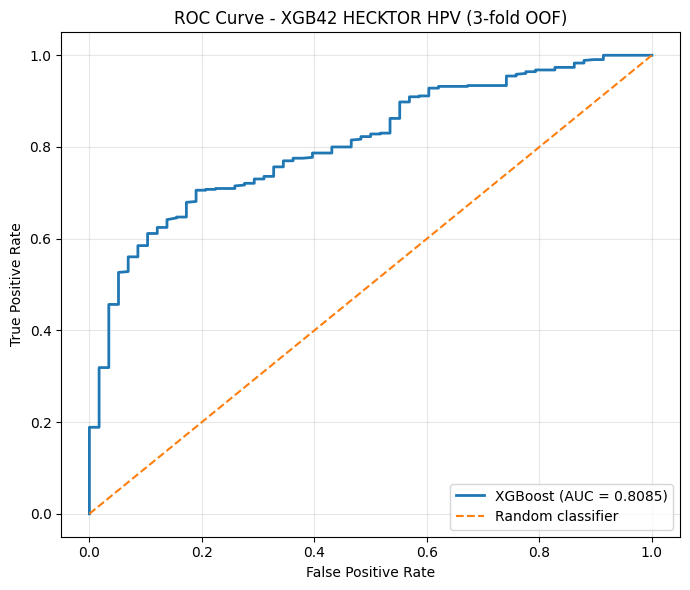

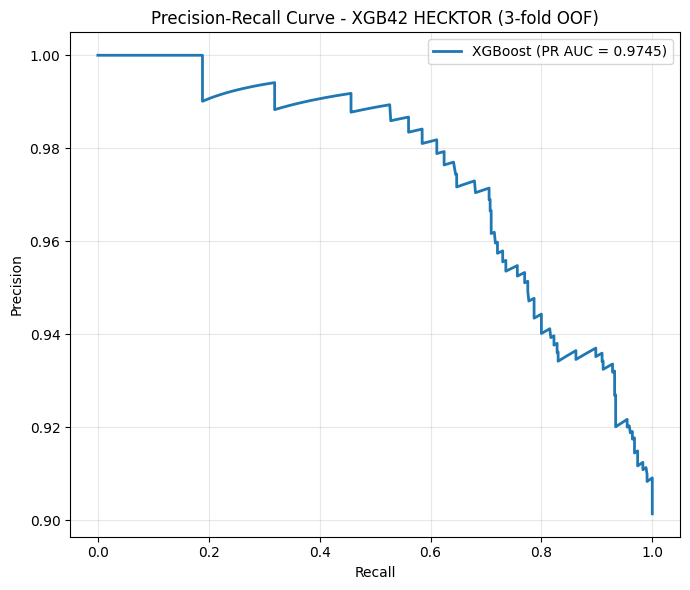


Combined original-feature importance:
            feature  importance_mean  importance_sd
            T-stage         0.440475       0.025396
            N-stage         0.213784       0.091623
 Performance Status         0.101812       0.066107
            M-stage         0.072805       0.064946
Tobacco Consumption         0.055772       0.013944
Alcohol Consumption         0.050514       0.001107
             Gender         0.034111       0.021118
                Age         0.030727       0.002965


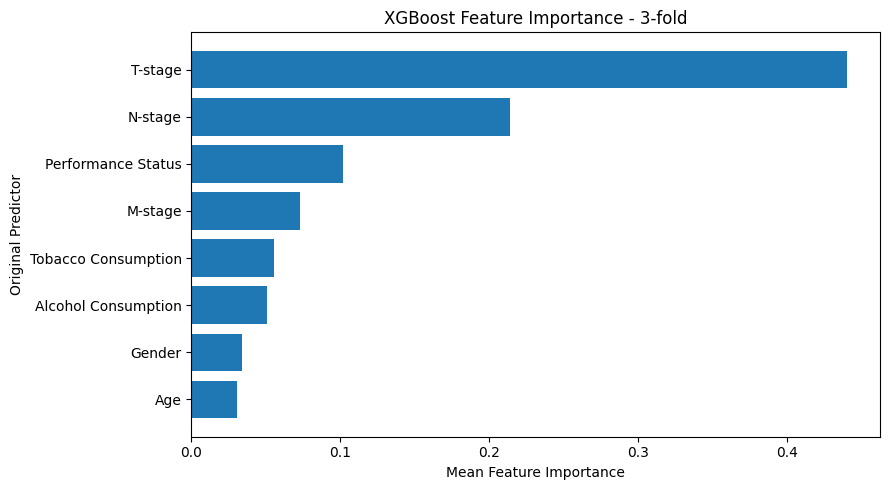

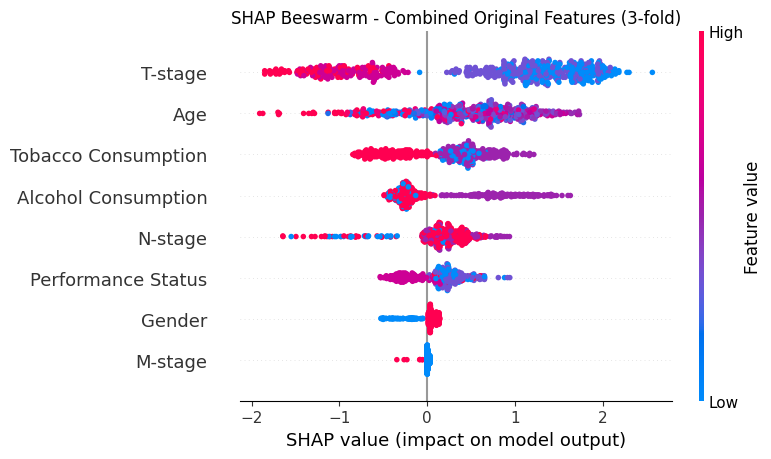


Mean absolute SHAP importance:
            feature  mean_abs_SHAP
            T-stage       1.208805
                Age       0.677537
Tobacco Consumption       0.469052
Alcohol Consumption       0.428584
            N-stage       0.302313
 Performance Status       0.266771
             Gender       0.090752
            M-stage       0.011805

Mean absolute LIME contribution:
            feature  mean_abs_LIME  sd_abs_LIME
            T-stage       0.065616     0.009334
Tobacco Consumption       0.042137     0.015358
            N-stage       0.041865     0.029244
 Performance Status       0.039912     0.011083
                Age       0.036769     0.005099
Alcohol Consumption       0.025211     0.007032
            M-stage       0.018414     0.018812
             Gender       0.004639     0.000172


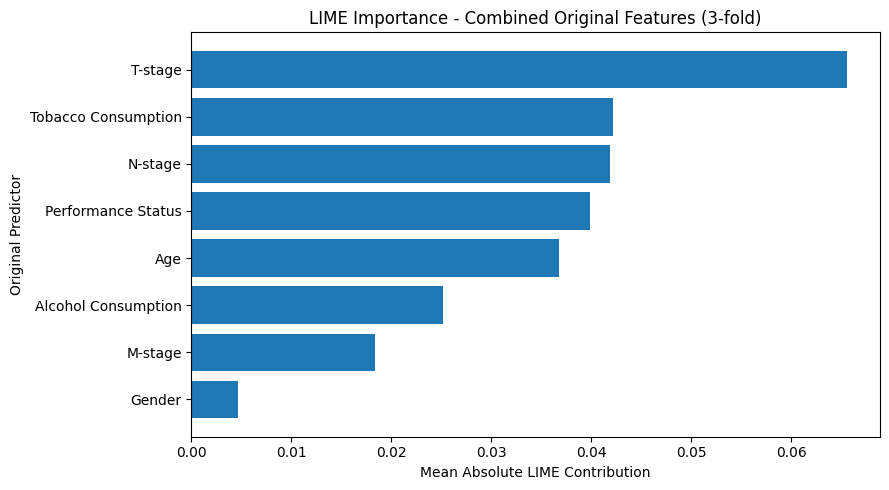


XGB42_HECKTOR 3-FOLD CV SUMMARY
Model: XGBoost
Original predictors: 8
Encoded features: 23
Estimators: 100
Learning rate: 0.1
Random state: 42
Folds: 3
Independent test set: None
Excluded predictors: RFS, Relapse, Treatment
SMOTE: No
Encoding: OneHotEncoder(handle_unknown='ignore')
Scaling: StandardScaler on Age only
Threshold: Validation balanced accuracy
SHAP: Mean across folds; combined original predictors
LIME: Mean absolute grouped contributions across folds

Pooled out-of-fold metrics:
Accuracy             0.6582
Balanced_Accuracy    0.7797
Precision            0.9881
Recall               0.6283
F1                   0.7682
Threshold            0.7450
ROC_AUC              0.8085
PR_AUC               0.9745
dtype: float64

Saved results folder: /content/drive/MyDrive/XGB_results_HECKTOR_3fold
Analysis complete.


In [1]:
!pip install -q gdown xgboost shap lime

# ============================================================
# XGB42_HECKTOR — XGBOOST HPV CLASSIFICATION
# 3-fold CV | 8 predictors | Seed 42 | No SMOTE | No test set
# ============================================================
import os,json,random,warnings,joblib,gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,
    precision_score,recall_score,f1_score,roc_auc_score,
    average_precision_score,confusion_matrix,classification_report,
    roc_curve,precision_recall_curve)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)

# ------------------------------------------------------------
# 1. LOAD AND PREPARE HECKTOR DATA
# ------------------------------------------------------------
from google.colab import drive
drive.mount("/content/drive")
gdown.download(id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
               output="HPV2025.xlsx",quiet=False)
df=pd.read_excel("HPV2025.xlsx")
df=df.dropna(subset=["HPV Status"]).copy()
columns_to_drop=["PatientID","CenterID","Task 1","Task 2","Task 3"]
df=df.drop(columns=[c for c in columns_to_drop if c in df.columns],
           errors="ignore")

# ------------------------------------------------------------
# 2. NORMALISE THE TARGET LABEL
# ------------------------------------------------------------
def normalize_label(value):
    if pd.isna(value):
        return np.nan
    label=str(value).strip().lower()
    if label in {"1","1.0","positive","pos","true","yes"}:
        return 1
    if label in {"0","0.0","negative","neg","false","no"}:
        return 0
    return np.nan

df["HPV_Label"]=df["HPV Status"].apply(normalize_label)
df=df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"]=df["HPV_Label"].astype(int)

# ------------------------------------------------------------
# 3. DEFINE PREDICTORS
# ------------------------------------------------------------
features=["Age","Gender","Tobacco Consumption","Alcohol Consumption",
          "Performance Status","T-stage","N-stage","M-stage"]
missing_columns=[c for c in features if c not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required predictor columns: {missing_columns}")
model_df=df[features+["HPV_Label"]].copy()
numeric_features=["Age"]
categorical_features=[c for c in features if c not in numeric_features]
missing_strings={"","nan","none","null","na","n/a"}
for col in categorical_features:
    def clean_category(value):
        if pd.isna(value):
            return np.nan
        value=str(value).strip()
        return np.nan if value.lower() in missing_strings else value
    model_df[col]=model_df[col].apply(clean_category)
model_df["Age"]=pd.to_numeric(model_df["Age"],errors="coerce")
print("Dataset shape:",model_df.shape)
print("\nPredictors:",features)
print("\nTarget distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())
if model_df["HPV_Label"].nunique()!=2:
    raise ValueError("The dataset must contain both HPV classes.")
if model_df["HPV_Label"].value_counts().min()<3:
    raise ValueError("Each class must contain at least 3 cases for 3-fold CV.")

# ------------------------------------------------------------
# 4. STRATIFIED 3-FOLD CROSS-VALIDATION
# ------------------------------------------------------------
X=model_df[features].reset_index(drop=True)
y=model_df["HPV_Label"].to_numpy()
skf=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
thresholds=np.linspace(0.10,0.90,161)
fold_metrics=[]
fold_models=[]
fold_preprocessors=[]
fold_thresholds=[]
fold_importances=[]
shap_values_all=[]
shap_data_all=[]
lime_fold_means=[]
oof_prob=np.full(len(y),np.nan)
oof_pred=np.full(len(y),-1,dtype=int)

def make_preprocessor():
    try:
        onehot=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
    except TypeError:
        onehot=OneHotEncoder(handle_unknown="ignore",sparse=False)
    return ColumnTransformer(transformers=[
        ("num",Pipeline([
            ("imputer",SimpleImputer(strategy="median")),
            ("scaler",StandardScaler())]),numeric_features),
        ("cat",Pipeline([
            ("imputer",SimpleImputer(strategy="most_frequent")),
            ("onehot",onehot)]),categorical_features)],
        remainder="drop",verbose_feature_names_out=False)

def calculate_metrics(y_true,probabilities,predictions,threshold):
    both_classes=len(np.unique(y_true))==2
    return {
        "Accuracy":accuracy_score(y_true,predictions),
        "Balanced_Accuracy":balanced_accuracy_score(y_true,predictions),
        "Precision":precision_score(y_true,predictions,zero_division=0),
        "Recall":recall_score(y_true,predictions,zero_division=0),
        "F1":f1_score(y_true,predictions,zero_division=0),
        "Threshold":float(threshold),
        "ROC_AUC":roc_auc_score(y_true,probabilities) if both_classes else np.nan,
        "PR_AUC":average_precision_score(y_true,probabilities)
        if both_classes else np.nan}

def original_name(encoded_name):
    return encoded_name.split("__")[-1]

def grouped_shap(values,names):
    grouped=np.zeros((values.shape[0],len(features)))
    for j,feature in enumerate(features):
        indices=[i for i,name in enumerate(names)
                 if (original_name(name)==feature if feature=="Age"
                 else original_name(name).startswith(feature+"_"))]
        if indices:
            grouped[:,j]=values[:,indices].sum(axis=1)
    return grouped

category_maps={
    col:{value:i for i,value in enumerate(
        sorted(model_df[col].dropna().astype(str).unique()))}
    for col in categorical_features}

def grouped_display_data(raw):
    display=raw[features].copy()
    for col in categorical_features:
        display[col]=display[col].map(category_maps[col]).fillna(-1)
    display["Age"]=pd.to_numeric(display["Age"],errors="coerce")
    return display.fillna(-1).to_numpy(dtype=float)

for fold,(train_idx,val_idx) in enumerate(skf.split(X,y),start=1):
    print(f"\n{'='*18} FOLD {fold}/3 {'='*18}")
    X_train_raw=X.iloc[train_idx]
    X_val_raw=X.iloc[val_idx]
    y_train,y_val=y[train_idx],y[val_idx]
    preprocessor=make_preprocessor()
    X_train=preprocessor.fit_transform(X_train_raw)
    X_val=preprocessor.transform(X_val_raw)
    try:
        encoded_names=preprocessor.get_feature_names_out().tolist()
    except (AttributeError,TypeError):
        encoded_names=[f"encoded_feature_{i}" for i in range(X_train.shape[1])]
    n_features=X_train.shape[1]
    counts=np.bincount(y_train,minlength=2)
    if np.any(counts==0):
        raise ValueError("Both HPV classes must be present in each training fold.")
    class_weights={i:float(len(y_train)/(2*counts[i])) for i in range(2)}
    scale_pos_weight=float(counts[0]/counts[1])
    print("Training samples:",len(y_train))
    print("Validation samples:",len(y_val))
    print("Automatic class weights:",class_weights)
    print("XGBoost scale_pos_weight:",scale_pos_weight)
    print("SMOTE: No")

    # --------------------------------------------------------
    # 5. TRAIN XGBOOST — ORIGINAL PARAMETERS
    # --------------------------------------------------------
    model=XGBClassifier(n_estimators=100,learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,random_state=SEED,
        eval_metric="logloss")
    model.fit(X_train,y_train)

    # --------------------------------------------------------
    # 6. SELECT THRESHOLD USING EACH VALIDATION FOLD
    # --------------------------------------------------------
    val_prob=model.predict_proba(X_val)[:,1]
    threshold_scores=[
        balanced_accuracy_score(y_val,(val_prob>=t).astype(int))
        for t in thresholds]
    best_score=max(threshold_scores)
    best_threshold=float(min(
        (t for t,s in zip(thresholds,threshold_scores) if s==best_score),
        key=lambda t:abs(t-0.5)))
    val_pred=(val_prob>=best_threshold).astype(int)
    metrics=calculate_metrics(y_val,val_prob,val_pred,best_threshold)
    metrics.update({"Fold":fold,"N_Train":len(train_idx),
        "N_Validation":len(val_idx),"Scale_Pos_Weight":scale_pos_weight})
    fold_metrics.append(metrics)
    fold_thresholds.append(best_threshold)
    oof_prob[val_idx]=val_prob
    oof_pred[val_idx]=val_pred
    fold_models.append(model)
    fold_preprocessors.append(preprocessor)
    print("Selected threshold:",round(best_threshold,3))
    print("\nValidation metrics:")
    print(pd.Series(metrics).round(4))

    # --------------------------------------------------------
    # 7. FEATURE IMPORTANCE — GROUPED ORIGINAL PREDICTORS
    # --------------------------------------------------------
    importance=[]
    for feature in features:
        indices=[i for i,name in enumerate(encoded_names)
                 if (original_name(name)==feature if feature=="Age"
                 else original_name(name).startswith(feature+"_"))]
        importance.append(float(model.feature_importances_[indices].sum())
                          if indices else 0.0)
    fold_importances.append(importance)

    # --------------------------------------------------------
    # 8. SHAP — COMBINE ONE-HOT COLUMNS BY ORIGINAL FEATURE
    # --------------------------------------------------------
    explainer=shap.TreeExplainer(model)
    shap_result=explainer.shap_values(X_val)
    if isinstance(shap_result,list):
        shap_result=shap_result[1] if len(shap_result)>1 else shap_result[0]
    shap_result=np.asarray(shap_result)
    if shap_result.ndim==3:
        shap_result=shap_result[:,:,1]
    grouped_values=grouped_shap(shap_result,encoded_names)
    shap_values_all.append(grouped_values)
    shap_data_all.append(grouped_display_data(X_val_raw))

    # --------------------------------------------------------
    # 9. LIME — GROUP ENCODED COLUMNS BY ORIGINAL PREDICTOR
    # --------------------------------------------------------
    lime_explainer=LimeTabularExplainer(
        np.asarray(X_train),feature_names=encoded_names,
        class_names=["HPV Negative","HPV Positive"],
        mode="classification",discretize_continuous=False,
        random_state=SEED+fold)
    sample_count=min(50,len(X_val))
    sample_idx=np.linspace(0,len(X_val)-1,sample_count,dtype=int)
    lime_sums=np.zeros(len(features))
    for row_idx in sample_idx:
        explanation=lime_explainer.explain_instance(
            np.asarray(X_val[row_idx]),model.predict_proba,
            num_features=len(encoded_names),labels=(1,))
        for encoded_idx,weight in explanation.local_exp[1]:
            name=original_name(encoded_names[encoded_idx])
            for k,feature in enumerate(features):
                if ((feature=="Age" and name==feature) or
                    (feature!="Age" and name.startswith(feature+"_"))):
                    lime_sums[k]+=abs(weight)
                    break
    lime_fold_means.append(lime_sums/sample_count)

# ------------------------------------------------------------
# 10. FOLD METRICS — MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------
fold_metrics_df=pd.DataFrame(fold_metrics)
metric_columns=["Accuracy","Balanced_Accuracy","Precision","Recall",
                "F1","Threshold","ROC_AUC","PR_AUC"]
summary_df=pd.DataFrame({
    "Metric":metric_columns,
    "Mean":[fold_metrics_df[c].mean() for c in metric_columns],
    "SD":[fold_metrics_df[c].std(ddof=1) for c in metric_columns]})
print("\nFOLD METRICS:")
print(fold_metrics_df.round(4).to_string(index=False))
print("\n3-FOLD MEAN ± SD:")
print(summary_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 11. POOLED OUT-OF-FOLD METRICS
# ------------------------------------------------------------
oof_metrics=calculate_metrics(y,oof_prob,oof_pred,float(np.mean(fold_thresholds)))
print("\nPOOLED OUT-OF-FOLD METRICS:")
print(pd.Series(oof_metrics).round(4))
cm=confusion_matrix(y,oof_pred,labels=[0,1])
print("\nConfusion matrix:\n",cm)
print("\nClassification report:\n",classification_report(
    y,oof_pred,labels=[0,1],
    target_names=["HPV Negative","HPV Positive"],zero_division=0))

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------
OUT_DIR="/content/drive/MyDrive/XGB_results_HECKTOR_3fold"
os.makedirs(OUT_DIR,exist_ok=True)
fold_metrics_df.to_csv(os.path.join(OUT_DIR,"fold_metrics.csv"),index=False)
summary_df.to_csv(os.path.join(OUT_DIR,"metrics_mean_sd.csv"),index=False)
predictions_df=pd.DataFrame({
    "y_true":y,"oof_probability_positive":oof_prob,"oof_prediction":oof_pred})
predictions_df.to_csv(os.path.join(OUT_DIR,"oof_predictions.csv"),index=False)
settings={
    "model":"XGBClassifier","dataset":"HPV2025.xlsx","seed":SEED,
    "folds":3,"features":features,"numeric_features":numeric_features,
    "categorical_features":categorical_features,"target_column":"HPV Status",
    "excluded_predictors":["RFS","Relapse","Treatment"],
    "thresholds":"161 values from 0.10 to 0.90",
    "threshold_selection":"Maximum validation balanced accuracy",
    "scale_pos_weight":"Training-fold negative/positive ratio",
    "smote":False,"test_set":False,
    "model_parameters":{"n_estimators":100,"learning_rate":0.1,
                        "eval_metric":"logloss"},
    "preprocessing":{
        "numeric":"Median imputation and StandardScaler; training fold only",
        "categorical":"Most-frequent imputation and OneHotEncoder; training fold only"},
    "cv":"StratifiedKFold(n_splits=3,shuffle=True,random_state=42)"}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f:
    json.dump(settings,f,indent=2)
joblib.dump({"models":fold_models,"preprocessors":fold_preprocessors,
    "features":features,"thresholds":fold_thresholds},
    os.path.join(OUT_DIR,"XGB42_HECKTOR_3fold_models.joblib"))

# ------------------------------------------------------------
# 13. ROC CURVE — POOLED OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------
fpr,tpr,_=roc_curve(y,oof_prob)
auc_curve=roc_auc_score(y,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"XGBoost (AUC = {auc_curve:.4f})")
plt.plot([0,1],[0,1],linestyle="--",linewidth=1.5,
         label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGB42 HECKTOR HPV (3-fold OOF)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curve_oof.png"),dpi=300,
            bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 14. PRECISION-RECALL CURVE — POOLED OOF
# ------------------------------------------------------------
precision_values,recall_values,_=precision_recall_curve(y,oof_prob)
pr_auc_curve=average_precision_score(y,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(recall_values,precision_values,linewidth=2,
         label=f"XGBoost (PR AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGB42 HECKTOR (3-fold OOF)")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"precision_recall_curve_oof.png"),
            dpi=300,bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 15. XGBOOST FEATURE IMPORTANCE — ORIGINAL PREDICTORS
# ------------------------------------------------------------
feature_importance=pd.DataFrame({
    "feature":features,
    "importance_mean":np.mean(fold_importances,axis=0),
    "importance_sd":np.std(fold_importances,axis=0,ddof=1)
}).sort_values("importance_mean",ascending=False)
feature_importance.to_csv(
    os.path.join(OUT_DIR,"feature_importance_combined.csv"),index=False)
print("\nCombined original-feature importance:")
print(feature_importance.to_string(index=False))
plot_importance=feature_importance.sort_values("importance_mean")
plt.figure(figsize=(9,5))
plt.barh(plot_importance["feature"],plot_importance["importance_mean"])
plt.xlabel("Mean Feature Importance")
plt.ylabel("Original Predictor")
plt.title("XGBoost Feature Importance - 3-fold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"feature_importance_combined.png"),
            dpi=300,bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 16. SHAP BEESWARM — EIGHT COMBINED ORIGINAL PREDICTORS
# ------------------------------------------------------------
all_shap_values=np.vstack(shap_values_all)
all_shap_data=np.vstack(shap_data_all)
shap_importance=pd.DataFrame({
    "feature":features,
    "mean_abs_SHAP":np.mean(np.abs(all_shap_values),axis=0)
}).sort_values("mean_abs_SHAP",ascending=False)
shap_importance.to_csv(
    os.path.join(OUT_DIR,"shap_mean_importance.csv"),index=False)
shap_explanation=shap.Explanation(
    values=all_shap_values,data=all_shap_data,feature_names=features)
plt.figure(figsize=(9,6))
shap.plots.beeswarm(shap_explanation,max_display=len(features),show=False)
plt.title("SHAP Beeswarm - Combined Original Features (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_beeswarm_combined.png"),
            dpi=300,bbox_inches="tight")
plt.show()
print("\nMean absolute SHAP importance:")
print(shap_importance.to_string(index=False))

# ------------------------------------------------------------
# 17. LIME — MEAN ABSOLUTE CONTRIBUTION ACROSS THREE FOLDS
# ------------------------------------------------------------
lime_mean=np.mean(lime_fold_means,axis=0)
lime_sd=np.std(lime_fold_means,axis=0,ddof=1)
lime_df=pd.DataFrame({
    "feature":features,"mean_abs_LIME":lime_mean,"sd_abs_LIME":lime_sd
}).sort_values("mean_abs_LIME",ascending=False)
lime_df.to_csv(os.path.join(OUT_DIR,"lime_mean_importance.csv"),index=False)
print("\nMean absolute LIME contribution:")
print(lime_df.to_string(index=False))
lime_plot=lime_df.sort_values("mean_abs_LIME")
plt.figure(figsize=(9,5))
plt.barh(lime_plot["feature"],lime_plot["mean_abs_LIME"])
plt.xlabel("Mean Absolute LIME Contribution")
plt.ylabel("Original Predictor")
plt.title("LIME Importance - Combined Original Features (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"lime_mean_importance.png"),
            dpi=300,bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 18. MODEL SUMMARY
# ------------------------------------------------------------
print("\n====================================")
print("XGB42_HECKTOR 3-FOLD CV SUMMARY")
print("====================================")
print("Model: XGBoost")
print("Original predictors:",len(features))
print("Encoded features:",n_features)
print("Estimators:",fold_models[0].n_estimators)
print("Learning rate:",fold_models[0].learning_rate)
print("Random state:",SEED)
print("Folds: 3")
print("Independent test set: None")
print("Excluded predictors: RFS, Relapse, Treatment")
print("SMOTE: No")
print("Encoding: OneHotEncoder(handle_unknown='ignore')")
print("Scaling: StandardScaler on Age only")
print("Threshold: Validation balanced accuracy")
print("SHAP: Mean across folds; combined original predictors")
print("LIME: Mean absolute grouped contributions across folds")
print("\nPooled out-of-fold metrics:")
print(pd.Series(oof_metrics).round(4))
print("\nSaved results folder:",OUT_DIR)
print("Analysis complete.")